# ML Model with actual goals

In [149]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import xgboost as xgb
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [150]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


def closed_form_solution(X, y):
    # alternative: np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))
    return np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))


def h(X, w):
    res = np.matmul(X, w)
    if type(res) == float:
        return res
    return res[0]


In [151]:
df_matches = pd.read_csv('matches_ac.csv', sep=';')

all_features = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "ht_curr_chancediff", "at_curr_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_curr_chanceamount", "at_curr_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value", "at_market_value",
    "ht_market_value_ln", "at_market_value_ln"
]

ga_best_features = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount"
]

gd_best_features = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]

ga_feature_set_heuer = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount"
]

gd_feature_set_heuer = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff", 
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness", 
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]
                  
ga_label = ["actual_goalamount"]
gd_label = ["actual_goaldiff"]

df_matches


,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,...,ht_last_year_chanceamount,at_last_year_chanceamount,ht_market_value,at_market_value,ht_market_value_ln,at_market_value_ln,xg_amount,xg_diff,actual_goalamount,actual_goaldiff
0,ENG,14,1,Queens Park Rangers,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,112000000,117000000,18.534009,18.577684,3.018240,0.783100,1,-1
1,ENG,14,1,Newcastle,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,140000000,452000000,18.757153,19.929193,2.446113,-0.514947,2,-2
2,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,53000000,557000000,17.785802,20.138076,2.501101,-1.758819,4,-2
3,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,415000000,97000000,19.843789,18.390222,1.712261,1.395959,3,1
4,ENG,14,1,West Ham,Tottenham,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,136000000,304000000,18.728165,19.532538,2.870160,0.836040,1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,...,4.210526,4.473684,55000000,55000000,17.822844,17.822844,0.585014,0.537046,0,0
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,...,6.421053,4.157895,315000000,192000000,19.568083,19.073006,0.370430,0.221648,0,0
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,...,4.342105,8.789474,120000000,647000000,18.603002,20.287857,2.737759,-0.858041,5,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,...,7.131579,4.210526,618000000,106000000,20.241999,18.478950,4.515770,0.970270,3,1


## Remove outliers

In [152]:
df_matches_cleansed = df_matches.query("actual_goalamount <= 8 and actual_goaldiff <= 6 ").copy()

print("matches df:",df_matches.shape)
print("cleansed matches df:",df_matches_cleansed.shape)

matches df: (9130, 35)
cleansed matches df: (9096, 35)


## Data split

In [153]:
df_training, df_testing = df_matches.query(
    f"season < 18"), df_matches.query(f"season == 18")

df_training_cleansed = df_matches_cleansed.query(f"season < 18")

## XG Boost baseline

In [154]:
ga_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1,
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0,
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

gd_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1,
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0,
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

ga_model.fit(df_training[ga_feature_set_heuer], df_training[ga_label])
gd_model.fit(df_training[gd_feature_set_heuer], df_training[gd_label])

ga_preds = ga_model.predict(df_testing[ga_feature_set_heuer])
gd_preds = gd_model.predict(df_testing[gd_feature_set_heuer])

# Calculate MAE
ga_abs_error, gd_abs_error = 0, 0
for ga_pred, gd_pred, (index, row) in zip(ga_preds, gd_preds, df_testing.iterrows()):
    ga_abs_error += np.abs(ga_pred - row["actual_goalamount"])
    gd_abs_error += np.abs(gd_pred - row["actual_goaldiff"])

print("XGBoost regressor MSE goalamount:",
      ga_abs_error / NUM_OF_MATCHES_IN_A_SEASON)
print("XGBoost regressor MSE goaldifference:",
      gd_abs_error / NUM_OF_MATCHES_IN_A_SEASON)


XGBoost regressor MSE goalamount: 1.3195007203181497
XGBoost regressor MSE goaldifference: 1.2613394651954701


## K-Fold-Crossvalidation

In [155]:
def calc_mae(y_pred, y):
    mae = 0
    for pred, actual_value in zip(y_pred, y):
        mae += np.abs((pred[0] - actual_value))
    return mae / len(y)


In [168]:
class GeneralModel:
    def __init__(self):
        self.model = LinearRegression() 

    def fit(self, df, features, label):
        self.model.fit(df[features], df[label])

    def predict(self, df, features):
        return self.model.predict(df[features])

    def predict_single(self, row, features):
        return self.model.predict([row[features]])[0][0]


class WeightsPerMatchnumberModel:
    def __init__(self):
        self.models = []

    def fit(self, df, features, label):
        for i in range(1, 39):
            matchnumber_df = df.query(f"matchnumber == {i}")
            self.models.append(LinearRegression().fit(matchnumber_df[features],
                               matchnumber_df[label]))

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            preds.append(
                self.models[row["matchnumber"]-1].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        return self.models[row["matchnumber"]-1].predict([row[features]])[0]


class SectionedModel:
    def __init__(self):
        self.models = [LinearRegression(), LinearRegression(),
                       LinearRegression()]

    def fit(self, df, features, label):
        first_df = df.query(f"(country == 'GER' and matchnumber < 18) or (country != 'GER' and matchnumber < 20)")
        second_df = df.query(
            f"(country == 'GER' and matchnumber >= 18 and matchnumber < 31) or (country != 'GER' and matchnumber >= 20 and matchnumber < 35)")
        third_df = df.query(
            f"(country == 'GER' and matchnumber >= 31) or (country != 'GER' and matchnumber >= 35)")
        if not first_df.empty:
            self.models[0].fit(first_df[features], first_df[label])
        else:
            self.models[0].fit([np.ones(len(features))], [[1]])
        if not second_df.empty:
            self.models[1].fit(second_df[features], second_df[label])
        else:
            self.models[1].fit([np.ones(len(features))], [[1]])
        if not third_df.empty:
            self.models[2].fit(third_df[features], third_df[label])
        else:
            self.models[2].fit([np.ones(len(features))], [[1]])
        

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
                preds.append(self.models[0].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
                preds.append(self.models[1].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
                preds.append(self.models[2].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
            return self.models[0].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
            return self.models[1].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
            return self.models[2].predict([row[features]])[0][0]


In [157]:
# Validate over:
# Feature selection (3)
# general weights; weights per matchnumber; weights for first seasonhalf, second and last 4
# Train-Valid split per season (4)
do_crossvalidation = False

if do_crossvalidation:
    for data_name, train_df in zip(["full", "cleansed"],[df_matches, df_matches_cleansed]):
        for feature_set_name, feature_set in zip(["all", "heuer", "selection"],[(all_features, all_features), (ga_feature_set_heuer, gd_feature_set_heuer), (ga_best_features, gd_best_features)]):
            for weight_set_name in ["general", "per_match_no", "sectioned"]:
                ga_validation_error, gd_validation_error = 0, 0
                for season in range(14,18):
                    train_data, valid_data = train_df.query(
                        f"season != {season}"), train_df.query(f"season == {season}")

                    if weight_set_name == "general":
                        ga_model, gd_model = GeneralModel(), GeneralModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    if weight_set_name == "per_match_no":
                        ga_model, gd_model = WeightsPerMatchnumberModel(), WeightsPerMatchnumberModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    if weight_set_name == "sectioned":
                        ga_model, gd_model = SectionedModel(), SectionedModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    
                    ga_validation_error += (calc_mae(ga_model.predict(
                        valid_data, feature_set[0]), valid_data["actual_goalamount"])) * 0.25
                    gd_validation_error += (calc_mae(gd_model.predict(
                        valid_data, feature_set[1]), valid_data["actual_goaldiff"])) * 0.25

                print("%-8s %-9s %-12s " %
                    (data_name, feature_set_name, weight_set_name))
                print("ga validation error:", ga_validation_error)
                print("gd validation error:", gd_validation_error, end="\n\n")

# ga
# cleansed  heuer   sectioned
# ga validation error: 1.338160939892218
# gd validation error: 1.233728593417052

# gd
# cleansed  heuer   general
# ga validation error: 1.3478560646342541
# gd validation error: 1.2331060963059817


## Generate training error csv

In [170]:
do_a_training_error_run = True

if do_a_training_error_run:
      training_error_data = dict()
      ga_abs_training_error, gd_abs_training_error = 0,0
      prev_matchnumber = 0

      for index, row in df_training_cleansed.iterrows():
            if row["season"] == 14 and row["matchnumber"] == 1:
                  ga_pred, gd_pred = 0,0
            else:
                  if int(row["matchnumber"]) > prev_matchnumber:
                        curr_training_data_df = df_training_cleansed.query(
                            f"season < {row['season']} or (season == {row['season']} and matchnumber < {row['matchnumber']})")
                        ga_model = SectionedModel()
                        gd_model = GeneralModel()
                        ga_model.fit(curr_training_data_df,
                                     ga_feature_set_heuer, ga_label)
                        gd_model.fit(curr_training_data_df,
                                     gd_feature_set_heuer, gd_label)

                  ga_pred = ga_model.predict_single(
                      row, ga_feature_set_heuer)
                  gd_pred = gd_model.predict_single(
                      row, gd_feature_set_heuer)

            ht_score_pred, at_score_pred = score_from_amount_and_diff(ga_pred, gd_pred)
            actual_ht_score, actual_at_score = score_from_amount_and_diff(
                  row["actual_goalamount"], row["actual_goaldiff"])
            ga_abs_training_error += np.abs(ga_pred - row["actual_goalamount"])
            gd_abs_training_error += np.abs(gd_pred - row["actual_goaldiff"])

            if row["country"] not in training_error_data.keys():
                  training_error_data[row["country"]] = {}
            if row["season"] not in training_error_data[row["country"]].keys():
                  training_error_data[row["country"]][row["season"]] = {}
            if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                  training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]] = {"abs_error_ga":0,"abs_error_gd":0}
            if row["country"] == "GER":
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row["actual_goalamount"]) / 9
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row["actual_goaldiff"]) / 9
            else:
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row["actual_goalamount"]) / 10
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row["actual_goaldiff"]) / 10

      print("Training MAE ga",
            ga_abs_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
      print("Training MAE gd", gd_abs_training_error /
            (NUM_OF_MATCHES_IN_A_SEASON*4))


Training MAE ga 1.3178892015416481
Training MAE gd 1.2309279764563439


In [171]:
if do_a_training_error_run:
      print("country;season_matchnumber;abs_error_ga;abs_error_gd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  for c in training_error_data[a][b].keys():
                        print(a+";"+str(b)+"_"+str(c)+";" +
                              str(training_error_data[a][b][c]["abs_error_ga"])+";"+str(training_error_data[a][b][c]["abs_error_gd"]))


country;season_matchnumber;abs_error_ga;abs_error_gd
ENG;14_1;2.6;0.9999999999999999
ENG;14_2;1.353061224489796;0.9839225320539322
ENG;14_3;1.3900080861111128;1.38439333663857
ENG;14_4;1.859870677864268;1.3095633525759378
ENG;14_5;1.8532320007821959;1.4454741465198944
ENG;14_6;1.202866792962466;1.1214340776968361
ENG;14_7;0.8803022303374756;0.8335101169780521
ENG;14_8;1.2421663341916789;0.9079514185863751
ENG;14_9;1.0588451220155342;1.023075624529182
ENG;14_10;1.2962725699038318;0.874181823017376
ENG;14_11;1.036700177453609;1.1251267609032403
ENG;14_12;0.8633930861263184;0.8468263967753906
ENG;14_13;1.1512961189818163;0.7770304982232774
ENG;14_14;1.0024193830151367;1.0943855192658407
ENG;14_15;1.5301305982820659;1.0057404624765456
ENG;14_16;1.0499616127154248;0.9124218132073311
ENG;14_17;0.9294533203178145;1.0862838412923894
ENG;14_18;1.2167996758554758;0.8701297061072978
ENG;14_19;1.6420017011498447;0.961867903512807
ENG;14_20;2.1522687190025294;1.0896760028334318
ENG;14_21;0.98692752

## Final models

In [ ]:
ga_model = SectionedModel()
gd_model = GeneralModel()

ga_model.fit(df_training_cleansed, ga_feature_set_heuer, ga_label)
gd_model.fit(df_training_cleansed, gd_feature_set_heuer, gd_label)

print("Generalizazion error ga:", calc_mae(ga_model.predict(
    df_testing, ga_feature_set_heuer), df_testing["actual_goalamount"]))
print("Generalizazion error gd:", calc_mae(gd_model.predict(
    df_testing, gd_feature_set_heuer), df_testing["actual_goaldiff"]))



Generalizazion error ga: 1.3171693064163499
Generalizazion error gd: 1.251670417839017


## Plot training error

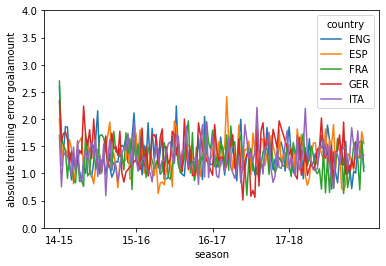

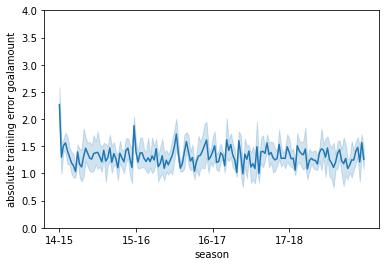

In [173]:
training_error_df = pd.read_csv('training_error.csv', sep=';')
sns.lineplot(data=training_error_df,
             x="season_matchnumber", y="abs_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()


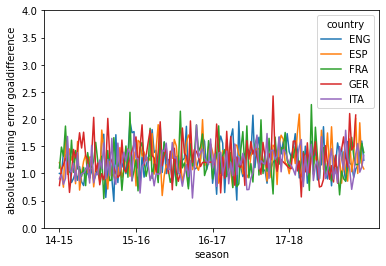

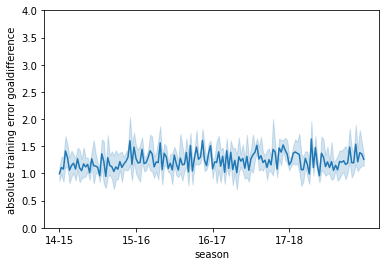

In [175]:
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()
